# VIX futures term structure: carry, tail risk, and the link to SOFR

**Two trading questions**

1. How much does the VIX futures (VX) curve pay you for being short volatility, and how do you survive the blow-ups?
2. When the VX curve inverts (risk-off), what happens to the SOFR curve and to Fed pricing, and does VIX lead?

This notebook tells the story step by step. All the code lives in `src/vixcarry/`; the notebook only calls it and
explains the results. The same numbers are produced by `python scripts/run_all.py`.

Conventions: VX in vol points (1 contract = $1,000 per point; tick 0.05 = $50). SOFR futures (SR3) as rates,
`rate = 100 - price`, in basis points. Signals use data up to the close of day *t*; trades happen at the close of
*t+1*. Every P&L is net of 1 tick + $2.50 per contract per side.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
%matplotlib inline
from vixcarry.config import load_config
from vixcarry import pipeline, plots
plots.style()
cfg = load_config()
o = pipeline.run(cfg, save=False)
k = o["key"]
print(f"Sample {k['sample_start']} to {k['sample_end']}: {len(o['ts'])} trading days")


Granger Causality
number of lags (no zero) 1
ssr based F test:         F=2.0927  , p=0.1482  , df_denom=2124, df_num=1
ssr based chi2 test:   chi2=2.0956  , p=0.1477  , df=1
likelihood ratio test: chi2=2.0946  , p=0.1478  , df=1
parameter F test:         F=2.0927  , p=0.1482  , df_denom=2124, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=4.3600  , p=0.0129  , df_denom=2121, df_num=2
ssr based chi2 test:   chi2=8.7405  , p=0.0126  , df=2
likelihood ratio test: chi2=8.7225  , p=0.0128  , df=2
parameter F test:         F=4.3600  , p=0.0129  , df_denom=2121, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=3.1325  , p=0.0247  , df_denom=2118, df_num=3
ssr based chi2 test:   chi2=9.4287  , p=0.0241  , df=3
likelihood ratio test: chi2=9.4078  , p=0.0243  , df=3
parameter F test:         F=3.1325  , p=0.0247  , df_denom=2118, df_num=3

Granger Causality
number of lags (no zero) 4
ssr based F test:         F=2.6265  , p=0.

## Step 1 - The term-structure dataset

For each day we take the live VX contracts (expiry after today), call them VX1, VX2, ..., and compute:

* **basis** = VX1 - spot VIX. Positive basis means the future is above spot; if nothing changes, the future drifts
  down to spot by expiry. That drift is what a short collects.
* **slope** = VX2 - VX1, and the **contango ratio** = VX2/VX1 - 1. Positive = normal upward-sloping curve.
* **roll yield** = basis / days to expiry: the drift per day, in vol points.
* **constant-maturity 30-day VX**: interpolate between the two contracts around 30 days, so the series does not
  jump at every expiry.

The heatmap shows every day's curve; red marks weeks when it was inverted.

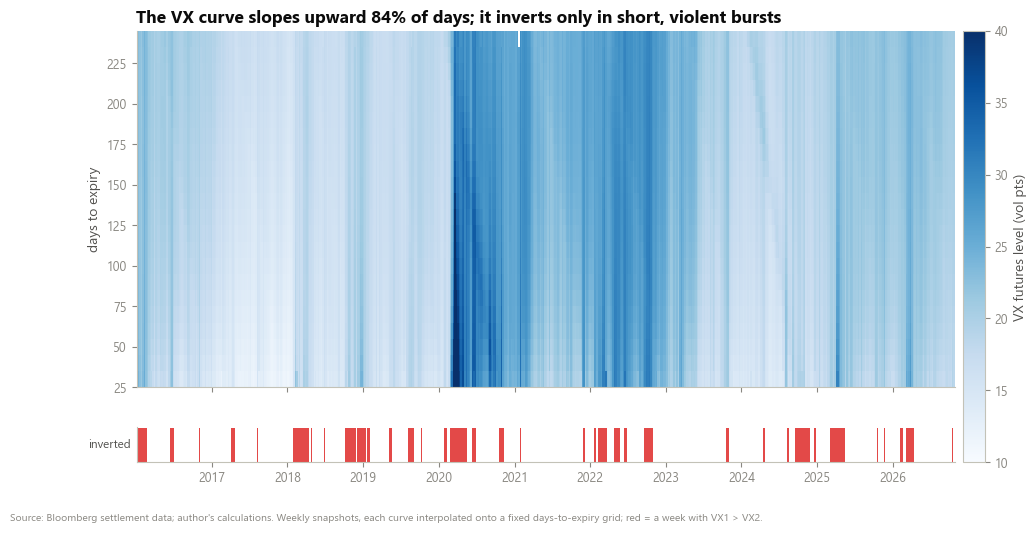

In [2]:
plots.heatmap(o, cfg);

In [3]:
print(f"Contango on {k['contango_share']:.0%} of days; average roll-down in contango "
      f"{k['avg_roll_yield_contango']:.3f} vol pts/day = ${k['avg_roll_yield_contango']*1000:,.0f} per contract per day")
o["contango_by_year"]

Contango on 84% of days; average roll-down in contango 0.069 vol pts/day = $69 per contract per day


,contango_share,avg_contango,avg_basis,avg_roll_yield,days
date,,,,,
2016,0.857,0.089,1.081,0.075,252
2017,0.944,0.090,1.120,0.095,251
2018,0.639,0.018,-0.082,-0.008,252
2019,0.897,0.067,0.811,0.053,252
2020,0.704,0.034,-0.270,-0.076,253
2021,0.992,0.098,1.238,0.081,252
2022,0.753,0.039,0.501,0.035,251
2023,0.988,0.075,0.900,0.060,251
2024,0.810,0.045,0.264,0.024,252


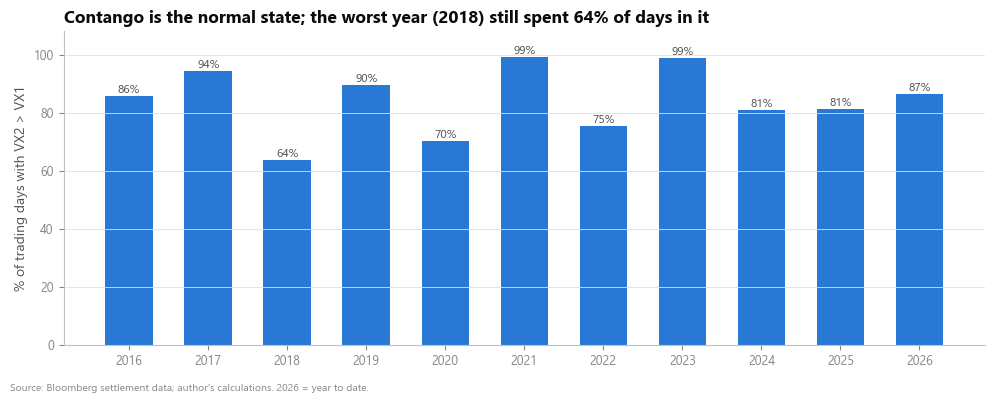

In [4]:
plots.contango_by_year(o, cfg);

**Why is there carry at all?** VIX itself is a price of insurance (implied volatility). Most of the time
implied volatility is above the volatility that actually happens next, the *variance risk premium*. The chart
compares VIX with the S&P 500's realised volatility over the following 21 days (S&P data here starts Nov-2020).

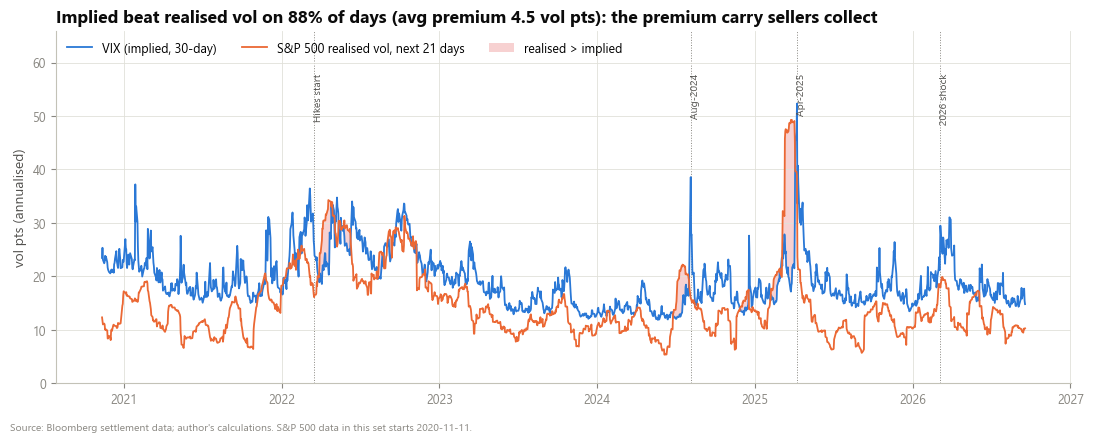

In [5]:
plots.vrp_chart(o, cfg);

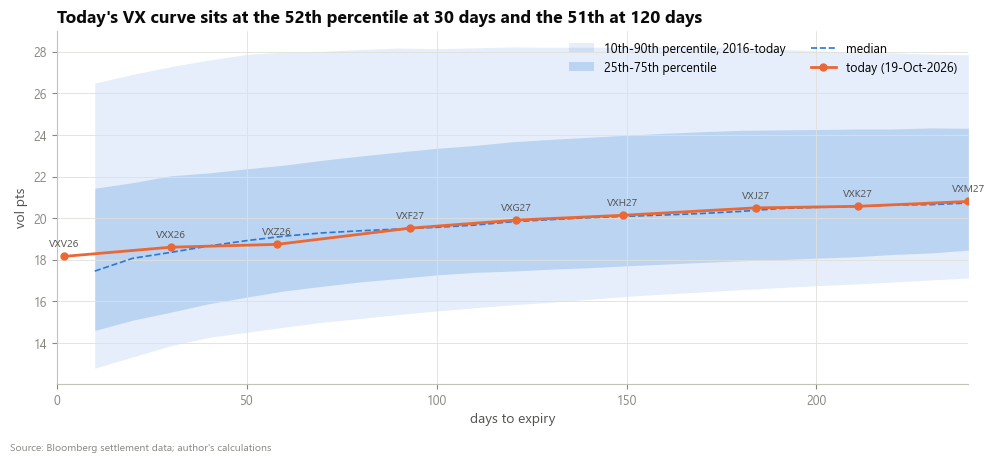

In [6]:
plots.curve_today(o, cfg);

## Step 2 - Carry strategies (backtests, net of costs)

Which contract: the nearest VX contract with **more than 5 business days to expiry** (fixed rule, known in advance).
We roll into the next one 5 days before expiry. P&L is always the change of the same contract's settle, so a roll
never creates a fake jump.

Variants, from naive to most defended:

| Variant | Rule |
|---|---|
| Short front, always | always short 1 lot |
| contango filter | short only when VX2/VX1 - 1 > threshold |
| + spike exit | also go flat (for 5 days) if the curve inverts or spot VIX jumps > 20% in a day |
| + spike exit + stop | also stop a trade after it loses X vol points |
| Contango > 0 + spike exit + stop | the same with the parameter-free threshold 0 (reference, not optimised) |
| Calendar 1:1 | short VX1-held / long the next contract, same filter and exits |
| Calendar beta-weighted | long beta x the next contract, beta from a 60-day regression |
| vol-targeted | size so the expected daily P&L s.d. is ~$1,000, max 10 lots |

**Parameter choice is in-sample only (2016-2021).** We try every threshold x stop and keep the best in-sample
Sharpe. 2022 onward is never looked at when choosing.

In [7]:
print(f"In-sample choice: contango threshold {o['threshold']:.1%}, stop {o['stop']:g} vol pts")
o["threshold_grid"].pivot(index="stop_volpts", columns="threshold", values="oos_sharpe").round(2)

In-sample choice: contango threshold 7.5%, stop 2 vol pts


threshold,0.000,0.025,0.050,0.075,0.100
stop_volpts,,,,,
1.0,0.22,0.23,-0.13,-0.29,-0.64
1.5,0.31,0.31,-0.10,-0.27,-0.60
2.0,0.32,0.31,-0.09,-0.27,-0.73
3.0,0.33,0.28,-0.10,-0.34,-0.73


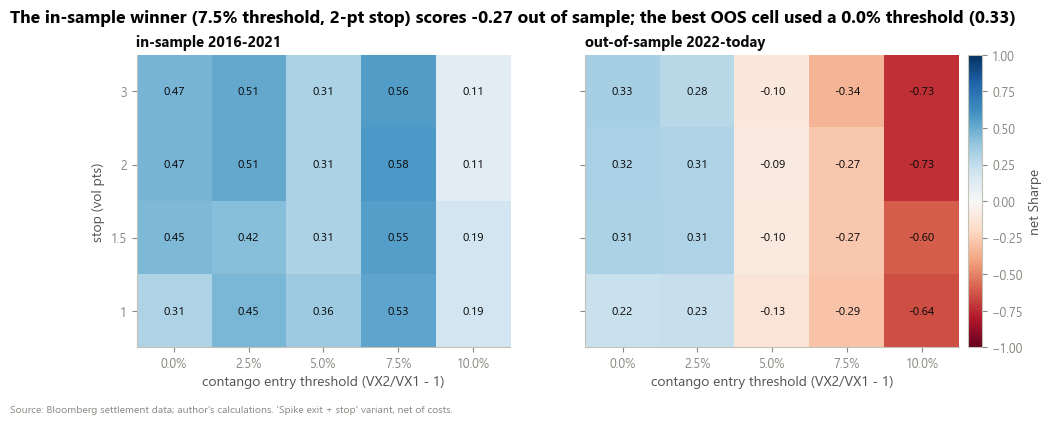

In [8]:
plots.robustness(o, cfg);

The heatmap is the most important honesty check in the project: the threshold that looked best in-sample
(7.5%) was among the worst afterwards, while the obvious, parameter-free rule (contango > 0) kept working. A
filter tuned on six years of history mostly learned the noise of those years.

In [9]:
s = o["summary"]
cols = ["strategy", "period", "trades", "hit_rate", "net_usd", "sharpe", "max_dd_usd", "worst_day_usd", "costs_usd"]
s[s.period != "full"][cols]

,strategy,period,trades,hit_rate,net_usd,sharpe,max_dd_usd,worst_day_usd,costs_usd
0,"Short front, always",in-sample,1,1.000,57471.200,0.422,-67935.000,-17600.000,7612.500
1,"Short front, always",out-of-sample,0,NaN,49543.500,0.584,-23732.200,-10245.900,6090.000
3,"Short front, contango filter",in-sample,54,0.519,24545.200,0.469,-8955.100,-6193.200,11707.500
4,"Short front, contango filter",out-of-sample,44,0.341,-6784.200,-0.220,-20932.200,-3709.800,8347.500
6,+ spike exit,in-sample,52,0.538,28365.500,0.561,-9725.000,-6193.200,10972.500
7,+ spike exit,out-of-sample,43,0.349,-10473.900,-0.343,-20932.200,-3709.800,8137.500
9,+ spike exit + stop,in-sample,52,0.558,29020.500,0.577,-9725.000,-6193.200,10867.500
10,+ spike exit + stop,out-of-sample,42,0.357,-8152.300,-0.270,-18867.300,-3709.800,8032.500
12,Contango > 0 + spike exit + stop,in-sample,38,0.474,35439.700,0.465,-19775.000,-13255.000,9502.500
13,Contango > 0 + spike exit + stop,out-of-sample,24,0.542,17422.200,0.321,-26144.800,-10298.400,7192.500


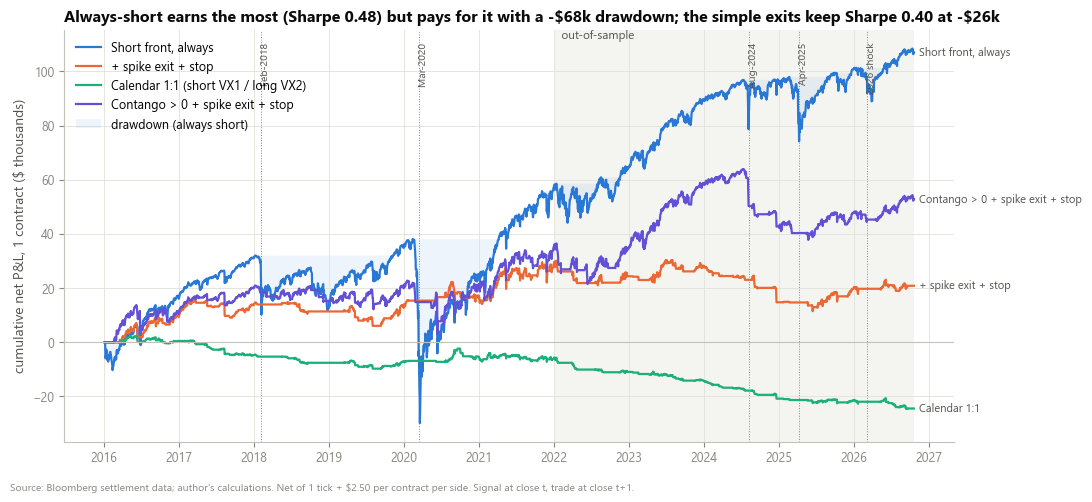

In [10]:
plots.equity_curves(o, cfg);

Where does the money go? Gross P&L versus costs over the full sample. The calendar spreads trade two legs on
every entry, exit and roll, so costs matter twice as much.

In [11]:
f = s[s.period == "full"].set_index("strategy")[["gross_usd", "costs_usd", "net_usd", "sharpe", "time_in_market"]]
f.round(2)

,gross_usd,costs_usd,net_usd,sharpe,time_in_market
strategy,,,,,
"Short front, always",120717.20,13702.5,107014.70,0.48,1.00
"Short front, contango filter",37816.00,20055.0,17761.00,0.21,0.47
+ spike exit,37001.60,19110.0,17891.60,0.22,0.46
+ spike exit + stop,39768.20,18900.0,20868.20,0.26,0.45
Contango > 0 + spike exit + stop,69556.90,16695.0,52861.90,0.40,0.76
Calendar 1:1 (short VX1 / long VX2),13786.20,38220.0,-24433.80,-0.87,0.46
Calendar beta-weighted,4168.14,44562.0,-40393.86,-1.87,0.45
"Spike exit + stop, vol-targeted",33369.70,24885.0,8484.70,0.08,0.45


### Tail analysis (mandatory)

Carry is paid for tail risk. The table shows what each strategy did inside each crisis window: P&L, worst day,
worst week, the drawdown that happened inside the window, and how many business days it took to regain the
previous high (`inf` = not yet regained).

In [12]:
t = o["tails"].dropna(subset=["pnl_usd"])
t[t.strategy.isin(list(plots.STRAT_COLOURS))].round(0)

,window,strategy,pnl_usd,worst_day_usd,worst_week_usd,max_dd_usd,recovery_bdays
8,Feb-2018 (Volmageddon),"Short front, always",-9905.0,-17600.0,-19700.0,-20900.0,452.0
11,Feb-2018 (Volmageddon),+ spike exit + stop,0.0,0.0,0.0,0.0,NaN
12,Feb-2018 (Volmageddon),Contango > 0 + spike exit + stop,-3057.0,-1402.0,-1703.0,-3157.0,143.0
13,Feb-2018 (Volmageddon),Calendar 1:1 (short VX1 / long VX2),0.0,0.0,0.0,0.0,NaN
16,Mar-2020 (Covid),"Short front, always",-35635.0,-15250.0,-36705.0,-67680.0,273.0
19,Mar-2020 (Covid),+ spike exit + stop,0.0,0.0,0.0,0.0,NaN
20,Mar-2020 (Covid),Contango > 0 + spike exit + stop,-6903.0,-3150.0,-6903.0,-6903.0,227.0
21,Mar-2020 (Covid),Calendar 1:1 (short VX1 / long VX2),0.0,0.0,0.0,0.0,NaN
24,Aug-2024 (yen carry),"Short front, always",1058.0,-10246.0,-16126.0,-16126.0,8.0
27,Aug-2024 (yen carry),+ spike exit + stop,1546.0,-991.0,-52.0,-991.0,2.0


Aug-2015 proxy (no front-month VX in the data before Dec-2015): {'contract': 'VXF16', 'pnl_usd': -4855.0, 'worst_day_usd': -1974.999999999998, 'max_dd_usd': -6724.999999999999}


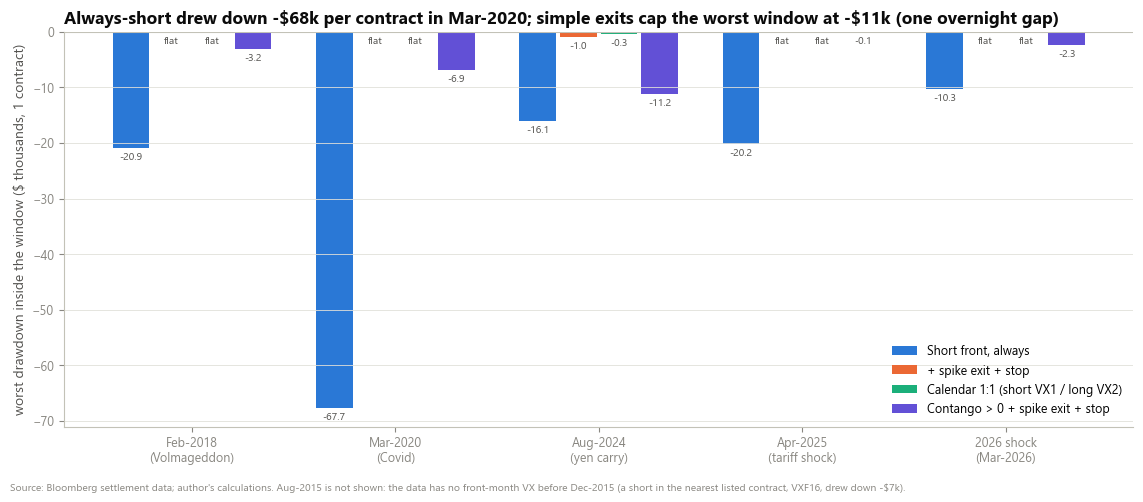

In [13]:
print("Aug-2015 proxy (no front-month VX in the data before Dec-2015):", o["aug2015_proxy"])
plots.tail_chart(o, cfg);

**Reading it.** Always-short is the best earner over the whole sample, but one contract lost about $68k from
peak in March 2020 and took more than a year to recover. The exits avoid the slow-motion disasters because the
curve usually flattens or inverts *before* the worst days, but they cannot avoid an overnight gap such as
5-Aug-2024, when VX jumped 10 points between two closes while the strategy was still short.

## Step 3 - Expiry seasonality

Line up every monthly cycle by business days to VX1 expiry and look at VX1 - VX2. The band is the 10-90th
percentile across cycles; orange is the current cycle.

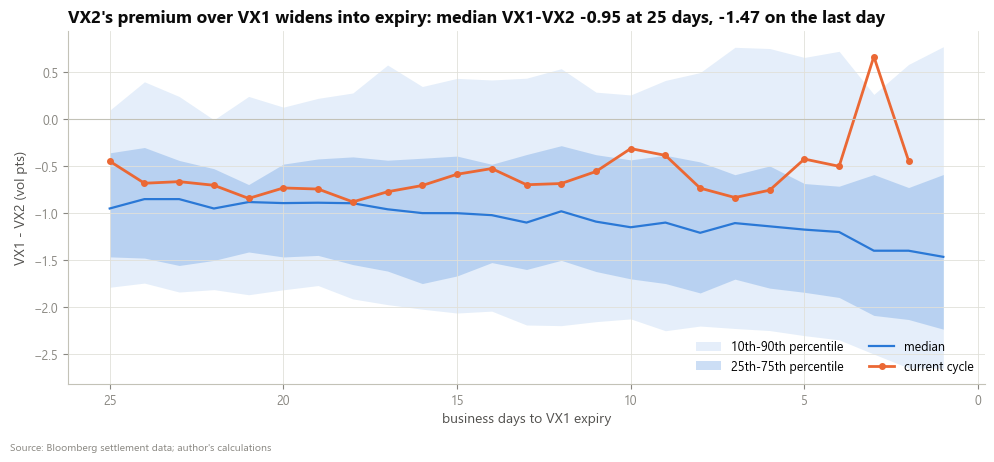

In [14]:
plots.seasonality(o, cfg);

In [15]:
o["season_spread"][["p10", "p25", "p50", "p75", "p90", "n"]].round(2)

,p10,p25,p50,p75,p90,n
bdte1,,,,,,
1,-2.65,-2.24,-1.47,-0.59,0.77,129
2,-2.65,-2.13,-1.40,-0.73,0.59,114
3,-2.50,-2.09,-1.40,-0.59,0.27,127
4,-2.35,-1.90,-1.20,-0.71,0.73,130
5,-2.31,-1.84,-1.18,-0.68,0.66,130
6,-2.25,-1.80,-1.14,-0.50,0.76,130
7,-2.23,-1.70,-1.11,-0.59,0.77,127
8,-2.20,-1.85,-1.21,-0.45,0.50,128
9,-2.25,-1.75,-1.10,-0.38,0.41,128


## Step 4 - Cross-asset: VIX -> rates

**Inversion events** = first day VX1 > VX2 after at least 20 days of contango. Around each event we measure, on
fixed contracts chained across rolls:

* the SR3 1-year spread (position 1 minus position 5, in rate terms),
* the SR3 4th quarterly contract's rate,
* the fed funds futures (ZQ) rate 12 months ahead minus the current month (negative = cuts priced).

The 2-year Treasury yield was planned too, but it is not populated in this data set (see `data/README.md`).

26 inversion events: 2016-06-13, 2016-11-02, 2017-04-06, 2017-08-10, 2018-02-02, 2018-06-25, 2018-10-09, 2019-05-07, 2019-08-05, 2019-10-08, 2020-01-27, 2020-10-21, 2021-01-27, 2021-12-03, 2022-01-21, 2022-04-26, 2022-09-21, 2023-10-19, 2024-04-15, 2024-08-05, 2024-09-18, 2025-03-03, 2025-10-15, 2025-11-17, 2026-02-05, 2026-10-16


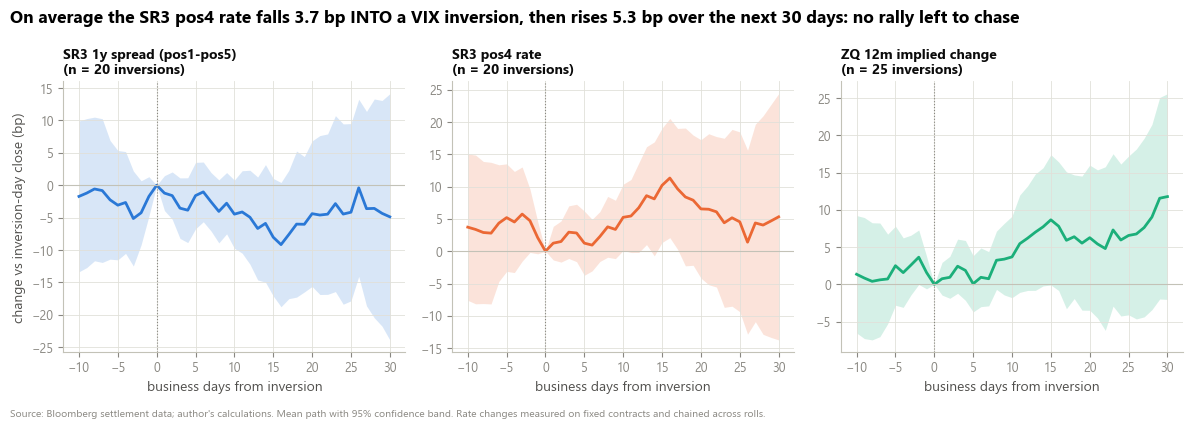

In [16]:
print(len(o["events"]), "inversion events:", ", ".join(str(d.date()) for d in o["events"]))
plots.event_study(o, cfg);

In [17]:
es = o["event_summary"]
es[es.offset.isin([-10, -5, 5, 10, 20, 30])].pivot(index="offset", columns="series", values="mean").round(1)

series,SR3 1y spread (pos1-pos5),SR3 pos4 rate,ZQ 12m implied change
offset,,,
-10,-1.7,3.7,1.4
-5,-3.1,5.2,2.5
5,-1.6,1.3,0.1
10,-4.5,5.2,3.7
20,-4.4,6.6,6.3
30,-4.9,5.3,11.8


Lead-lag: correlation of today's change in the VX slope with the SR3 2nd contract's rate change *lag* days
later, plus Granger tests in both directions.

,lag,F,p_value,test
0,1,2.093,0.148,VX slope -> SR3 pos2
1,2,4.360,0.013,VX slope -> SR3 pos2
2,3,3.132,0.025,VX slope -> SR3 pos2
3,4,2.627,0.033,VX slope -> SR3 pos2
4,5,1.968,0.081,VX slope -> SR3 pos2
5,1,1.710,0.191,SR3 pos2 -> VX slope
6,2,0.776,0.460,SR3 pos2 -> VX slope
7,3,1.240,0.293,SR3 pos2 -> VX slope
8,4,0.732,0.570,SR3 pos2 -> VX slope
9,5,0.642,0.668,SR3 pos2 -> VX slope


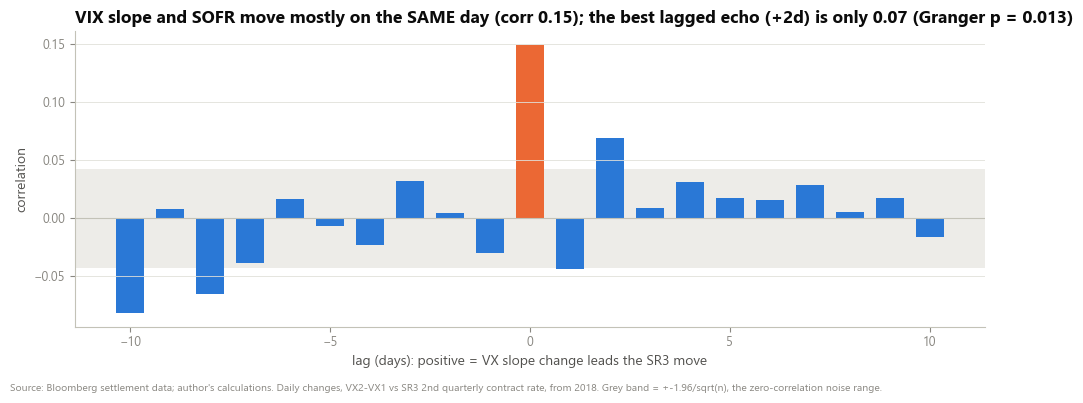

In [18]:
plots.leadlag(o, cfg);
o["granger"].round(4)

Conditional weeks: average weekly SR3 change by position in weeks when spot VIX rose more than 5 points,
versus all other weeks (2018 onward).

In [19]:
o["stress_weeks"].round(2)

,position,stress_weeks_bp,other_weeks_bp,difference_bp,t_stat,p_value,n_stress,n_other
0,pos1,-0.53,-0.12,-0.40,-1.36,0.18,27,415
1,pos2,-4.35,0.66,-5.02,-2.06,0.05,27,415
2,pos3,-6.39,1.34,-7.73,-2.27,0.03,27,415
3,pos4,-7.89,1.59,-9.48,-2.40,0.02,27,415
4,pos5,-8.69,1.70,-10.39,-2.48,0.02,27,415
5,pos6,-9.11,1.66,-10.77,-2.52,0.02,27,415
6,pos7,-9.41,1.57,-10.97,-2.64,0.01,27,415
7,pos8,-9.04,1.32,-10.36,-2.64,0.01,27,415


**Trading translation.** Buy (receive) the 4th SR3 contract at the close after each inversion and hold 20
business days, net of costs, versus doing the same trade on every day (the baseline).

In [20]:
o["sr3_translation"].round(2)

,period,events,avg_net_usd,hit_rate,total_net_usd,baseline_avg_net_usd,baseline_hit_rate
0,in-sample,9,114.44,0.44,1030.0,68.04,0.43
1,out-of-sample,11,-386.82,0.55,-4255.0,-298.34,0.35
2,all,20,-161.25,0.50,-3225.0,-137.90,0.39


## Conclusions

1. **The carry is real.** The VX curve is in contango on most days and VX1 drifts toward spot by about 0.07 vol
   points a day when it is; implied volatility exceeded the next month's realised volatility on most days.
2. **It is paid for crash risk.** A permanently short front contract has the best long-run P&L but drew down about
   $68k per contract in March 2020. Any desk running it needs a hard rule for the left tail.
3. **Simple defences work, tuned ones don't.** "Short only in contango, flat after an inversion or a 20% VIX jump"
   cut the worst crisis drawdown sharply and kept a positive out-of-sample Sharpe. The in-sample-optimised
   threshold failed out of sample: a lesson about over-fitting.
4. **Calendar spreads (short VX1 / long VX2) lose net**: VX2 rolls down too, so the long leg gives most of the
   carry back; the small gross profit left is smaller than the cost of trading two legs on every entry, exit and roll.
5. **VIX and SOFR move on the same day, not in sequence.** Stress weeks come with a significant SR3 rally, but by
   the time the VX curve inverts most of it has happened; buying SR3 after an inversion did not beat the baseline
   out of sample.